<a href="https://colab.research.google.com/github/Csahoo009/ML-for-DA/blob/main/T1%2C2%2C3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

# Load dataset directly from uploaded CSV
uploaded = files.upload()

import pandas as pd
df = pd.read_csv("indian_house_prices.csv")


# Convert Price to ₹ Lakhs (1 Lakh = 100,000 INR) for cleaner scale
df["Price_Lakhs"] = df["Price"] / 100000.0

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- First 5 Rows ---")
print(df[["City", "Location", "Area", "Price", "Price_Lakhs"]].head())

Saving indian_house_prices.csv to indian_house_prices.csv
Dataset Shape: 32963 rows, 42 columns

--- First 5 Rows ---
        City                         Location  Area     Price  Price_Lakhs
0  Bangalore                 JP Nagar Phase 1  3340  30000000       300.00
1  Bangalore       Dasarahalli on Tumkur Road  1045   7888000        78.88
2  Bangalore  Kannur on Thanisandra Main Road  1179   4866000        48.66
3  Bangalore                     Doddanekundi  1675   8358000        83.58
4  Bangalore                          Kengeri  1670   6845000        68.45


In [ ]:
# Check for missing values across all columns
missing_counts = df.isnull().sum()
print("Missing values in Area & Price_Lakhs:")
print(missing_counts[["Area", "Price_Lakhs"]])

# Clean missing values using mean imputation (if any exist)
df["Area"] = df["Area"].fillna(df["Area"].mean())
df["Price_Lakhs"] = df["Price_Lakhs"].fillna(df["Price_Lakhs"].mean())

print("\n Cleaned Dataset Overview")
print(df[["Area", "Price_Lakhs"]].describe())

# Select input feature (X) and target variable (y)
X = df[["Area"]]
y = df["Price_Lakhs"]

Missing values in Area & Price_Lakhs:
Area           0
Price_Lakhs    0
dtype: int64

--- Cleaned Dataset Overview ---
               Area   Price_Lakhs
count  32963.000000  32963.000000
mean    1293.362194    116.867181
std      763.703754    230.736815
min      200.000000     20.000000
25%      853.000000     40.715000
50%     1125.000000     67.110000
75%     1500.000000    120.000000
max    16000.000000   8545.999990


In [ ]:
print(f"Dataset shape before removing duplicates: {df.shape[0]} rows, {df.shape[1]} columns")
df.drop_duplicates(inplace=True)
print(f"Dataset shape after removing duplicates: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset shape before removing duplicates: 32963 rows, 42 columns
Dataset shape after removing duplicates: 29135 rows, 42 columns


In [ ]:
# Split dataset into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(f"Total dataset size: {len(df)} samples")
print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Total dataset size: 29135 samples
Training set size: 26370 samples
Testing set size: 6593 samples


In [ ]:
# Initialize and fit Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices for the test set
y_pred = model.predict(X_test)

# Display sample of actual vs predicted prices
results = pd.DataFrame({
    "Area (sq ft)": X_test["Area"].values,
    "Actual Price (₹ Lakhs)": y_test.values,
    "Predicted Price (₹ Lakhs)": np.round(y_pred, 2)
})

print("--- Actual vs Predicted Prices (First 10 Test Samples) ---")
print(results.head(10))

--- Actual vs Predicted Prices (First 10 Test Samples) ---
   Area (sq ft)  Actual Price (₹ Lakhs)  Predicted Price (₹ Lakhs)
0          1600                  160.00                     142.64
1          1000                   26.00                      91.08
2          1400                   24.00                     125.45
3          1510                   95.00                     134.91
4          1086                   48.00                      98.47
5           768                   36.00                      71.14
6          1900                  135.00                     168.42
7          1263                   50.17                     113.68
8          1250                  195.00                     112.56
9           685                   25.60                      64.00


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance Metrics ---")
print("Mean Absolute Error (MAE):", round(mae, 2), "Lakhs")
print("Root Mean Squared Error (RMSE):", round(rmse, 2), "Lakhs")
print("R2 Score:", round(r2, 4))

print("\n--- Regression Equation ---")
print(f"House Price (₹ Lakhs) = {round(model.intercept_, 2)} + {round(model.coef_[0], 4)} * Area")

--- Model Performance Metrics ---
Mean Absolute Error (MAE): 82.21 Lakhs
Root Mean Squared Error (RMSE): 220.78 Lakhs
R2 Score: 0.1082

--- Regression Equation ---
House Price (₹ Lakhs) = 5.13 + 0.0859 * Area


In [ ]:
# Configure 5-Fold Cross Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Compute cross-validation R2 scores across all 5 folds
cv_r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

# Compute cross-validation MSE scores
cv_mse_scores = -cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')

print("5-Fold Cross Validation Results")
print("R2 Scores per Fold:", np.round(cv_r2_scores, 4))
print("Mean R2 Score across Folds:", round(cv_r2_scores.mean(), 4))
print("Mean MSE across Folds:", round(cv_mse_scores.mean(), 2))

5-Fold Cross Validation Results
R2 Scores per Fold: [0.1082 0.0938 0.0638 0.0693 0.0968]
Mean R2 Score across Folds: 0.0864
Mean MSE across Folds: 48660.48


Predicted price for a 2,100 sq. ft. house: ₹185.61 Lakhs


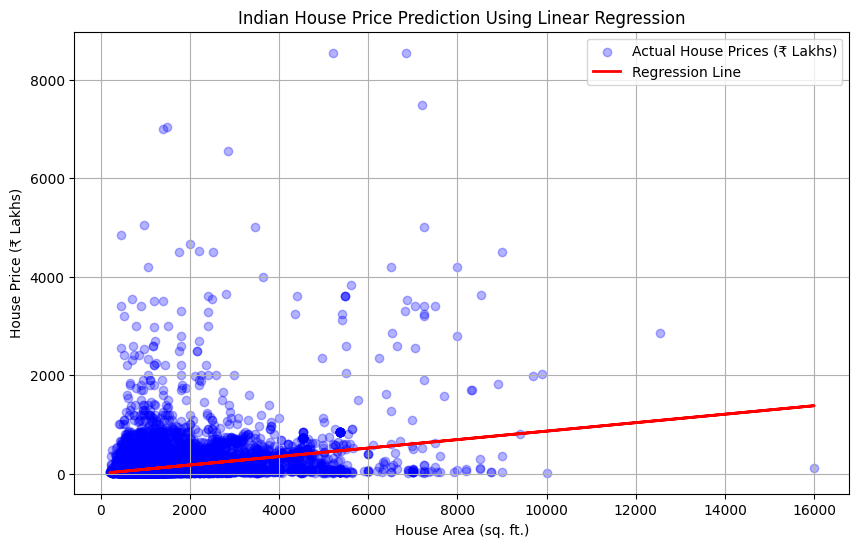

In [ ]:
# Predict price for a sample house of 2100 sq. ft.
new_house = pd.DataFrame({"Area": [2100]})
predicted_price = model.predict(new_house)

print(f"Predicted price for a 2,100 sq. ft. house: ₹{round(predicted_price[0], 2)} Lakhs")

# Plot Actual Data Points and Regression Line
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.3, label="Actual House Prices (₹ Lakhs)")
plt.plot(X, model.predict(X), color='red', linewidth=2, label="Regression Line")

plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price (₹ Lakhs)")
plt.title("Indian House Price Prediction Using Linear Regression")
plt.legend()
plt.grid(True)
plt.show()